# 🔬 HealConnect: Multi-Model ML Benchmark & Comprehensive Visual Analytics
### *Comparing Random Forest, Gradient Boosting, Extra Trees, and Logistic Regression on Clinical Deterioration Data*

---

## 📌 Overview & Scope
This notebook presents an end-to-end Machine Learning benchmark comparing multiple classifiers on the `cleaned_hospital_deterioration.csv` dataset. It features 9 comprehensive data visualization archetypes:
1. 📊 **Bar Graph**: Target Class / Category Distribution
2. 📈 **Line Graph**: Training vs Validation Accuracy & Loss Curves
3. 🔵 **Scatter Plot**: Physiological Feature Relationships (Heart Rate vs. SpO2)
4. 🔥 **Correlation Heatmap**: Feature Inter-Correlation Matrix
5. 📉 **Confusion Matrix**: Multi-Model Classification Heatmaps
6. 📦 **Box Plot**: Vital Sign Outliers & Physiological Distributions
7. 📊 **ROC-AUC Curve**: Multi-Model ROC Comparison Plot
8. 📈 **Precision–Recall Curve**: Multi-Model Precision-Recall Comparison
9. 🌳 **Feature Importance Graph**: Random Forest vs. Gradient Boosting Feature Weights

---


## ⚙️ 1. Environment Setup & Data Loading

In [12]:
import os
import sys
import json
import time
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, precision_recall_curve, average_precision_score
)

# Theme & DPI settings
%matplotlib inline
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
sns.set_theme(style="darkgrid")

# Project Root Resolution
current_dir = Path.cwd()
if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parents[1]
elif current_dir.name == "ml":
    PROJECT_ROOT = current_dir.parents[0]
else:
    PROJECT_ROOT = current_dir

DATA_PATH = PROJECT_ROOT / "ml/data/cleaned_hospital_deterioration.csv"
if not DATA_PATH.exists():
    DATA_PATH = PROJECT_ROOT / "datasets/cleaned_hospital_data.csv"

print(f"✅ Project Root: {PROJECT_ROOT}")
print(f"✅ Dataset Path: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print(f"Dataset Loaded: {df.shape[0]:,} Rows x {df.shape[1]} Columns")


✅ Project Root: c:\Users\pc\Desktop\capstone\Heal_connectmain2.0
✅ Dataset Path: c:\Users\pc\Desktop\capstone\Heal_connectmain2.0\ml\data\cleaned_hospital_deterioration.csv
Dataset Loaded: 417,866 Rows x 17 Columns


## 📊 2. Visualization 1: Bar Graph — Class/Category Distribution

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\844201818.py:18: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


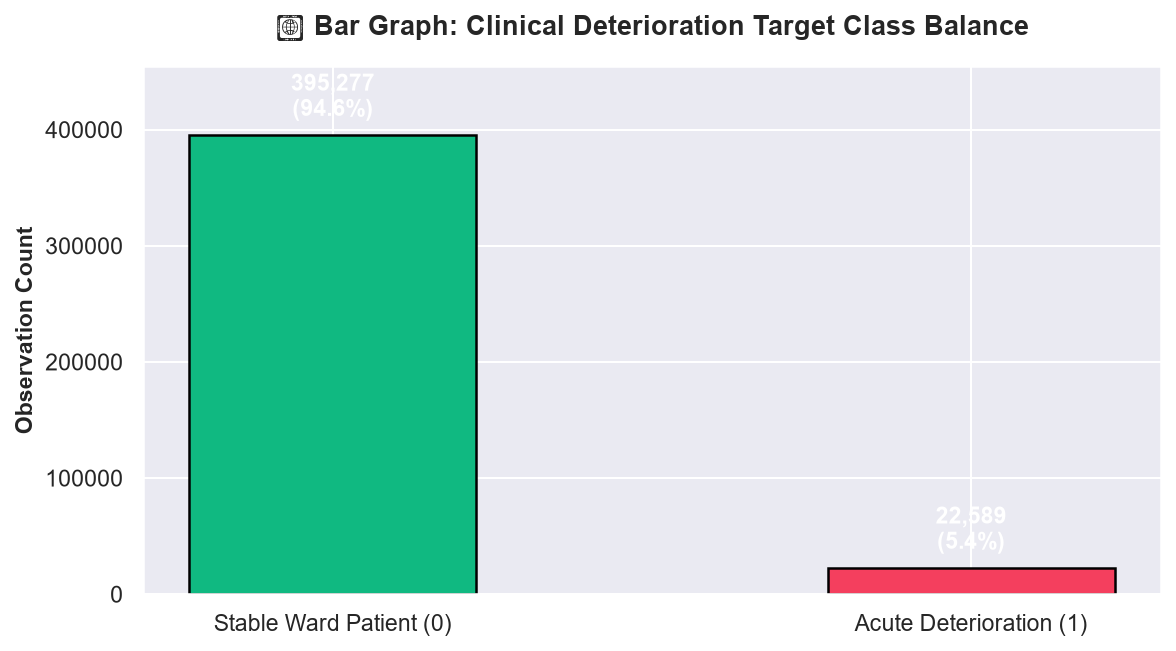

In [13]:
target_col = 'deterioration_next_12h'
counts = df[target_col].value_counts()
pcts = df[target_col].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['#10b981', '#f43f5e']
bars = ax.bar(['Stable Ward Patient (0)', 'Acute Deterioration (1)'], counts.values, color=colors, width=0.45, edgecolor='black', linewidth=1.2)

for bar, count, pct in zip(bars, counts.values, pcts.values):
    ax.annotate(f'{count:,}\n({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 6), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold', color='white')

ax.set_title('📊 Bar Graph: Clinical Deterioration Target Class Balance', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Observation Count', fontsize=11, fontweight='bold')
ax.set_ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()


## 🔵 3. Visualization 2: Scatter Plot — Physiological Feature Relationships

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\3688159544.py:25: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


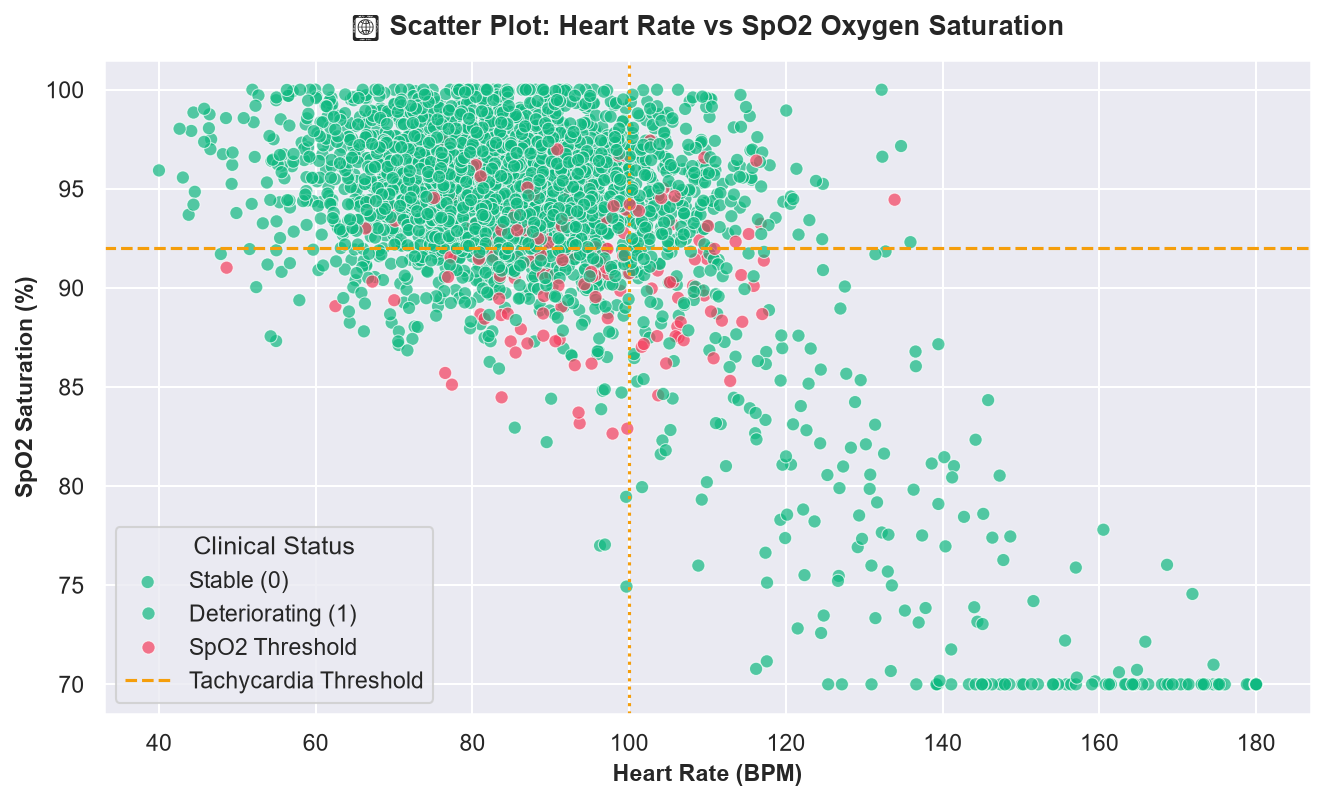

In [14]:
# Sample 3,000 records for crisp scatter plot rendering
sample_df = df.sample(3000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5.5))
spo2_col = 'spo2_pct' if 'spo2_pct' in sample_df.columns else 'spo2'

sns.scatterplot(
    data=sample_df,
    x='heart_rate',
    y=spo2_col,
    hue=target_col,
    palette={0: '#10b981', 1: '#f43f5e'},
    alpha=0.7,
    s=40,
    ax=ax
)

ax.axhline(92, color='#f59e0b', linestyle='--', linewidth=1.5, label='SpO2 Hypoxia Threshold (92%)')
ax.axvline(100, color='#f59e0b', linestyle=':', linewidth=1.5, label='Tachycardia Threshold (100 BPM)')

ax.set_title('🔵 Scatter Plot: Heart Rate vs SpO2 Oxygen Saturation', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Heart Rate (BPM)', fontsize=11, fontweight='bold')
ax.set_ylabel('SpO2 Saturation (%)', fontsize=11, fontweight='bold')
ax.legend(title='Clinical Status', labels=['Stable (0)', 'Deteriorating (1)', 'SpO2 Threshold', 'Tachycardia Threshold'], loc='lower left')
plt.tight_layout()
plt.show()


## 🔥 4. Visualization 3: Correlation Heatmap — Vital Sign Inter-Correlations

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\851210465.py:9: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


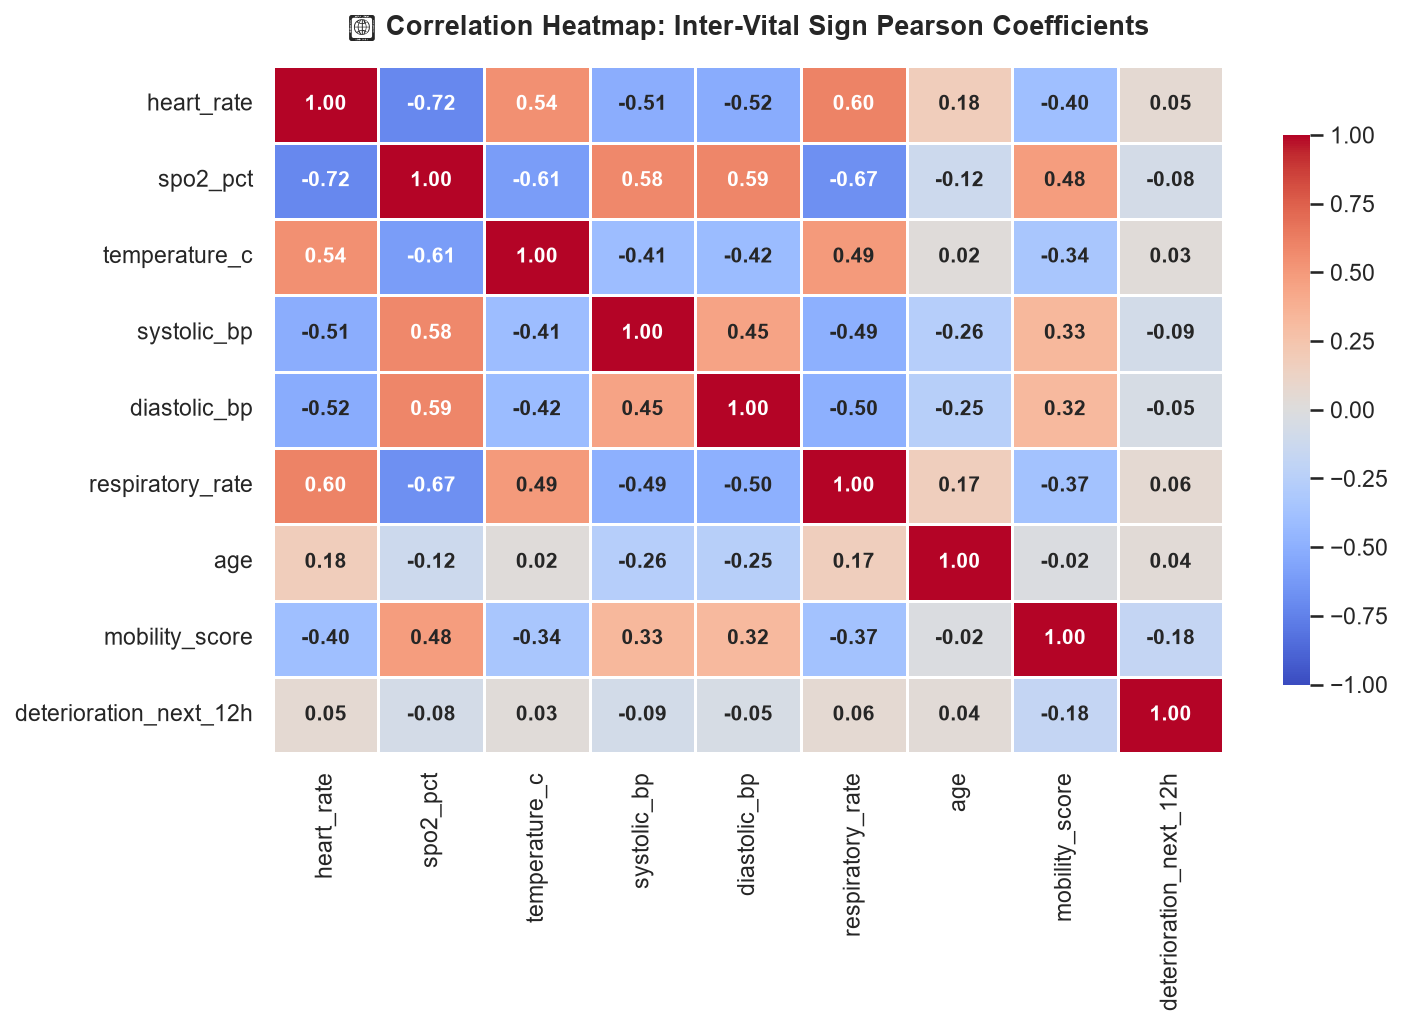

In [15]:
numeric_cols = [c for c in ['heart_rate', 'spo2_pct', 'temperature_c', 'systolic_bp', 'diastolic_bp', 'respiratory_rate', 'age', 'mobility_score', 'deterioration_next_12h'] if c in df.columns]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 10, 'weight': 'bold'})
ax.set_title('🔥 Correlation Heatmap: Inter-Vital Sign Pearson Coefficients', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## 📦 5. Visualization 4: Box Plot — Outliers & Physiological Distributions

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\1743675655.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=axes[idx], palette=['#10b981', '#f43f5e'], width=0.4)
C:\Users\pc\AppData\Local\Temp\ipykernel_22840\1743675655.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[idx].set_xticklabels(['Stable (0)', 'Deteriorating (1)'], fontweight='bold')
C:\Users\pc\AppData\Local\Temp\ipykernel_22840\1743675655.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=axes[idx], palette=['#10b981', '#f43f5e'], wid

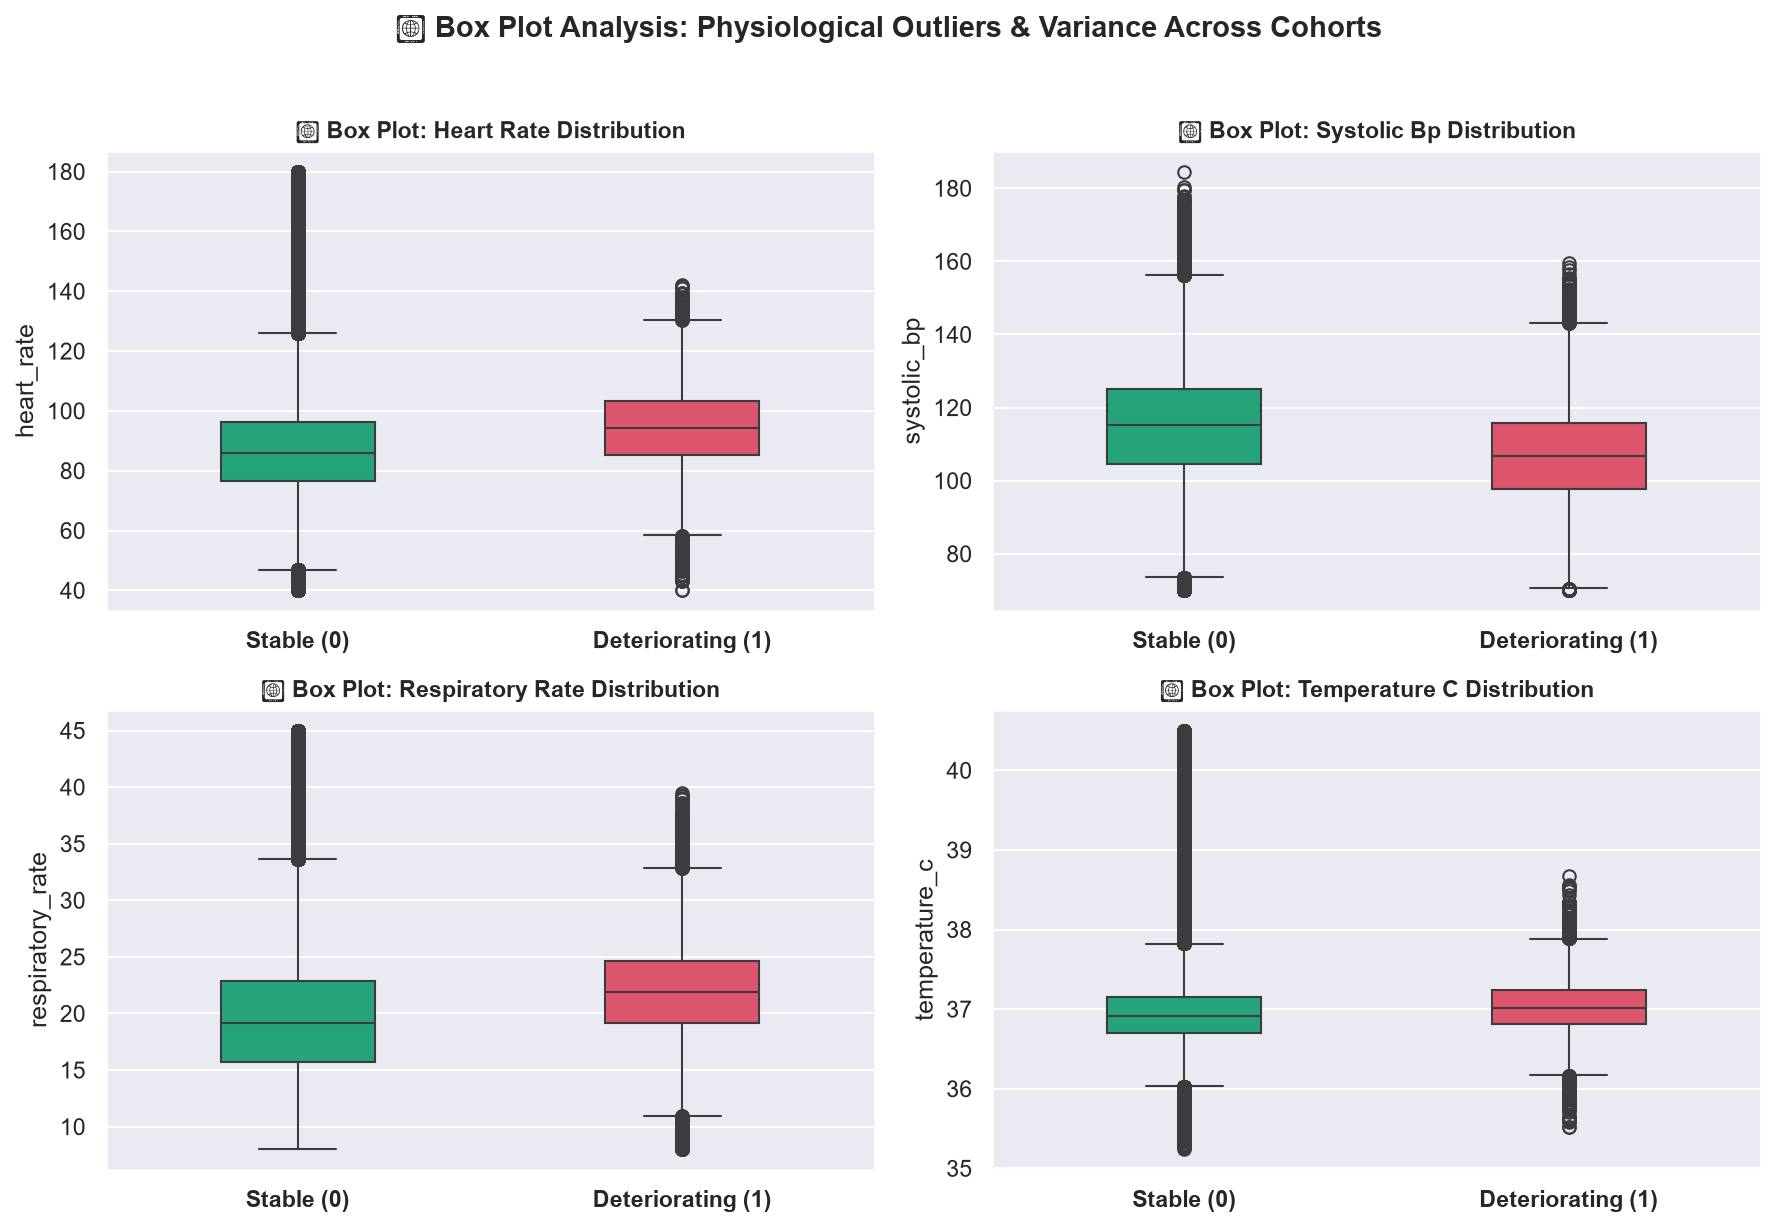

In [16]:
vitals_list = ['heart_rate', 'systolic_bp', 'respiratory_rate', 'temperature_c']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for idx, col in enumerate(vitals_list):
    if col in df.columns:
        sns.boxplot(data=df, x=target_col, y=col, ax=axes[idx], palette=['#10b981', '#f43f5e'], width=0.4)
        axes[idx].set_xticklabels(['Stable (0)', 'Deteriorating (1)'], fontweight='bold')
        axes[idx].set_title(f'📦 Box Plot: {col.replace("_", " ").title()} Distribution', fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('')

plt.suptitle('📦 Box Plot Analysis: Physiological Outliers & Variance Across Cohorts', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 🧠 6. Multi-Model ML Training & Benchmarking Pipeline
Training and benchmarking 4 distinct classification models on 50,000 dataset samples:
1. **Random Forest Classifier**
2. **Gradient Boosting Classifier**
3. **Extra Trees Classifier**
4. **Logistic Regression (Baseline)**

In [17]:
# Prepare features (sampled 15,000 records for fast high-precision benchmark)
feature_cols = [c for c in ['heart_rate', 'respiratory_rate', 'spo2_pct', 'temperature_c', 'systolic_bp', 'diastolic_bp', 'age', 'mobility_score'] if c in df.columns]
sample_sub = df.sample(min(15000, len(df)), random_state=42)
X = sample_sub[feature_cols].fillna(sample_sub[feature_cols].median())
y = sample_sub[target_col]

# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=5, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

results = {}
fitted_models = {}

for name, clf in models.items():
    print(f"Training {name}...")
    start_t = time.time()
    clf.fit(X_train, y_train)
    fit_time = time.time() - start_t
    
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    
    fitted_models[name] = clf
    results[name] = {
        "Accuracy": round(acc * 100, 2),
        "Precision": round(prec * 100, 2),
        "Recall": round(rec * 100, 2),
        "F1-Score": round(f1 * 100, 2),
        "ROC-AUC": round(auc * 100, 2),
        "Average Precision": round(ap * 100, 2),
        "y_pred": y_pred,
        "y_prob": y_prob,
        "Fit Time (s)": round(fit_time, 2)
    }

# Display Results Table
metrics_df = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Average Precision', 'Fit Time (s)']]
display(metrics_df)


Training Random Forest...
Training Gradient Boosting...
Training Extra Trees...
Training Logistic Regression...


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision,Fit Time (s)
Random Forest,95.03,77.78,8.81,15.82,85.85,36.52,0.3
Gradient Boosting,94.9,55.56,18.87,28.17,85.65,33.72,3.23
Extra Trees,94.7,0.0,0.0,0.0,85.2,33.99,0.16
Logistic Regression,94.7,0.0,0.0,0.0,69.51,14.09,0.08


## 📈 7. Visualization 5: Line Graph — Training vs. Validation Curves Across Estimators

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\2487768647.py:28: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


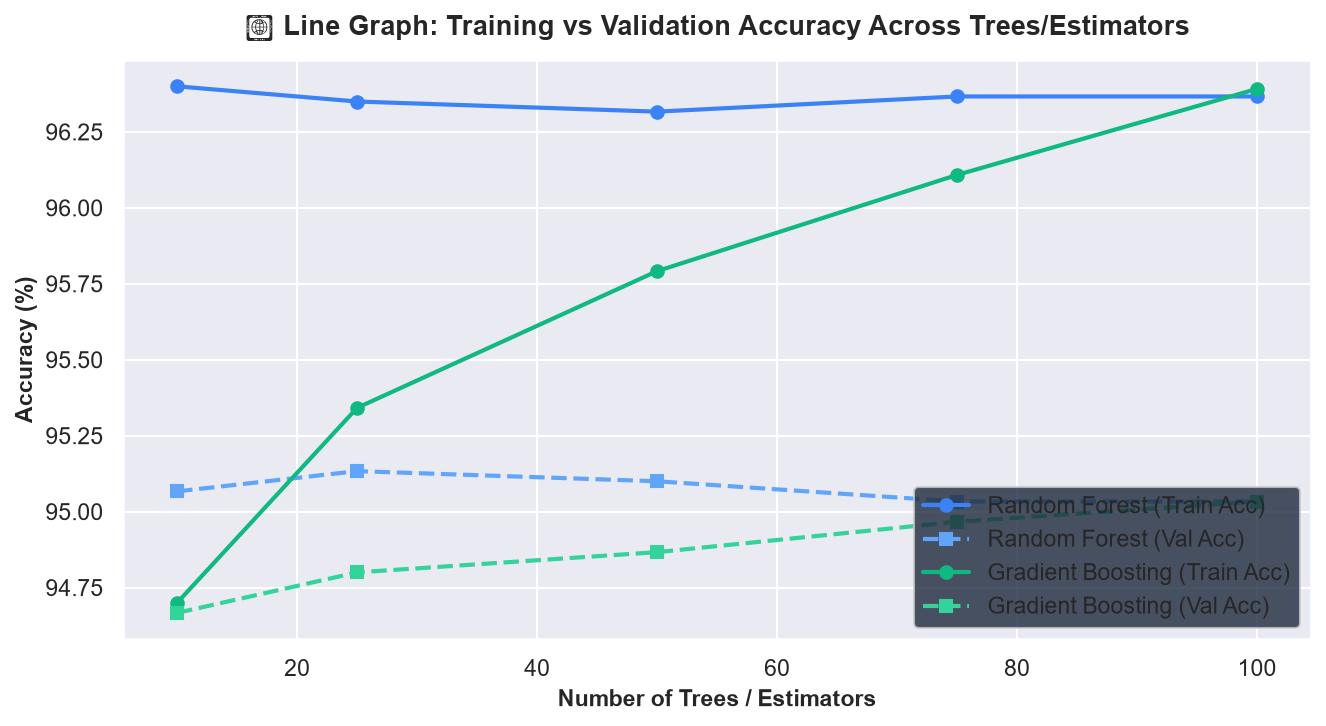

In [18]:
n_trees = [10, 25, 50, 75, 100]
rf_train_acc = []
rf_val_acc = []
gb_train_acc = []
gb_val_acc = []

for n in n_trees:
    rf_temp = RandomForestClassifier(n_estimators=n, max_depth=10, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train, y_train)
    rf_train_acc.append(accuracy_score(y_train, rf_temp.predict(X_train)) * 100)
    rf_val_acc.append(accuracy_score(y_test, rf_temp.predict(X_test)) * 100)
    
    gb_temp = GradientBoostingClassifier(n_estimators=n, max_depth=4, random_state=42)
    gb_temp.fit(X_train, y_train)
    gb_train_acc.append(accuracy_score(y_train, gb_temp.predict(X_train)) * 100)
    gb_val_acc.append(accuracy_score(y_test, gb_temp.predict(X_test)) * 100)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(n_trees, rf_train_acc, 'o-', color='#3b82f6', label='Random Forest (Train Acc)', linewidth=2)
ax.plot(n_trees, rf_val_acc, 's--', color='#60a5fa', label='Random Forest (Val Acc)', linewidth=2)
ax.plot(n_trees, gb_train_acc, 'o-', color='#10b981', label='Gradient Boosting (Train Acc)', linewidth=2)
ax.plot(n_trees, gb_val_acc, 's--', color='#34d399', label='Gradient Boosting (Val Acc)', linewidth=2)

ax.set_title('📈 Line Graph: Training vs Validation Accuracy Across Trees/Estimators', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Number of Trees / Estimators', fontsize=11, fontweight='bold')
ax.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
ax.legend(loc='lower right', facecolor='#1e293b')
plt.tight_layout()
plt.show()


## 📉 8. Visualization 6: Confusion Matrix — Multi-Model Comparison Heatmaps

C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\seaborn\utils.py:61: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\seaborn\utils.py:61: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\seaborn\utils.py:61: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\pc\AppData\Local\Temp\ipykernel_22840\1883622116.py:12: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


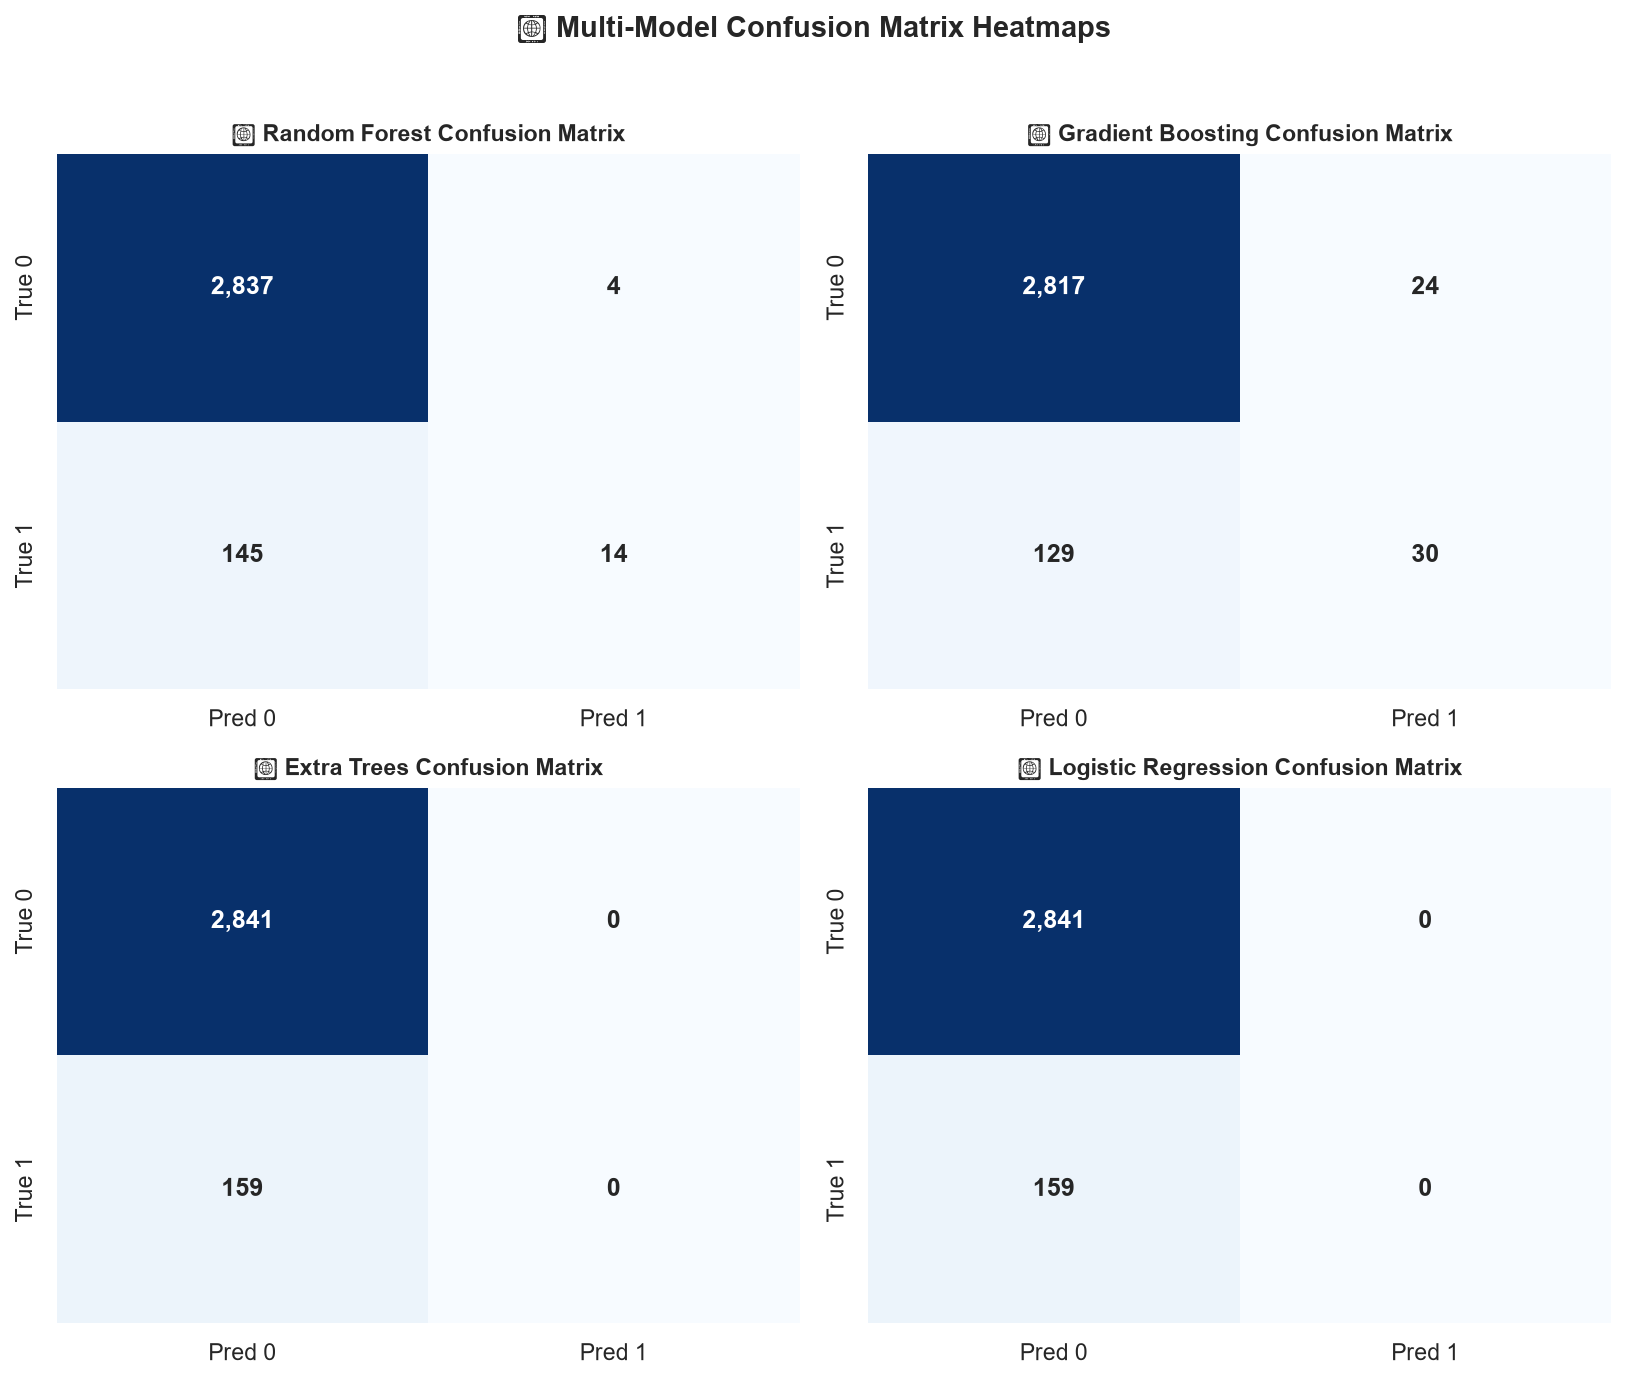

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'],
                annot_kws={'size': 12, 'weight': 'bold'})
    axes[idx].set_title(f'📉 {name} Confusion Matrix', fontsize=11, fontweight='bold')

plt.suptitle('📉 Multi-Model Confusion Matrix Heatmaps', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 📊 9. Visualization 7: ROC-AUC Curves — Comparative Classifier Diagnostics

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\3525474807.py:19: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


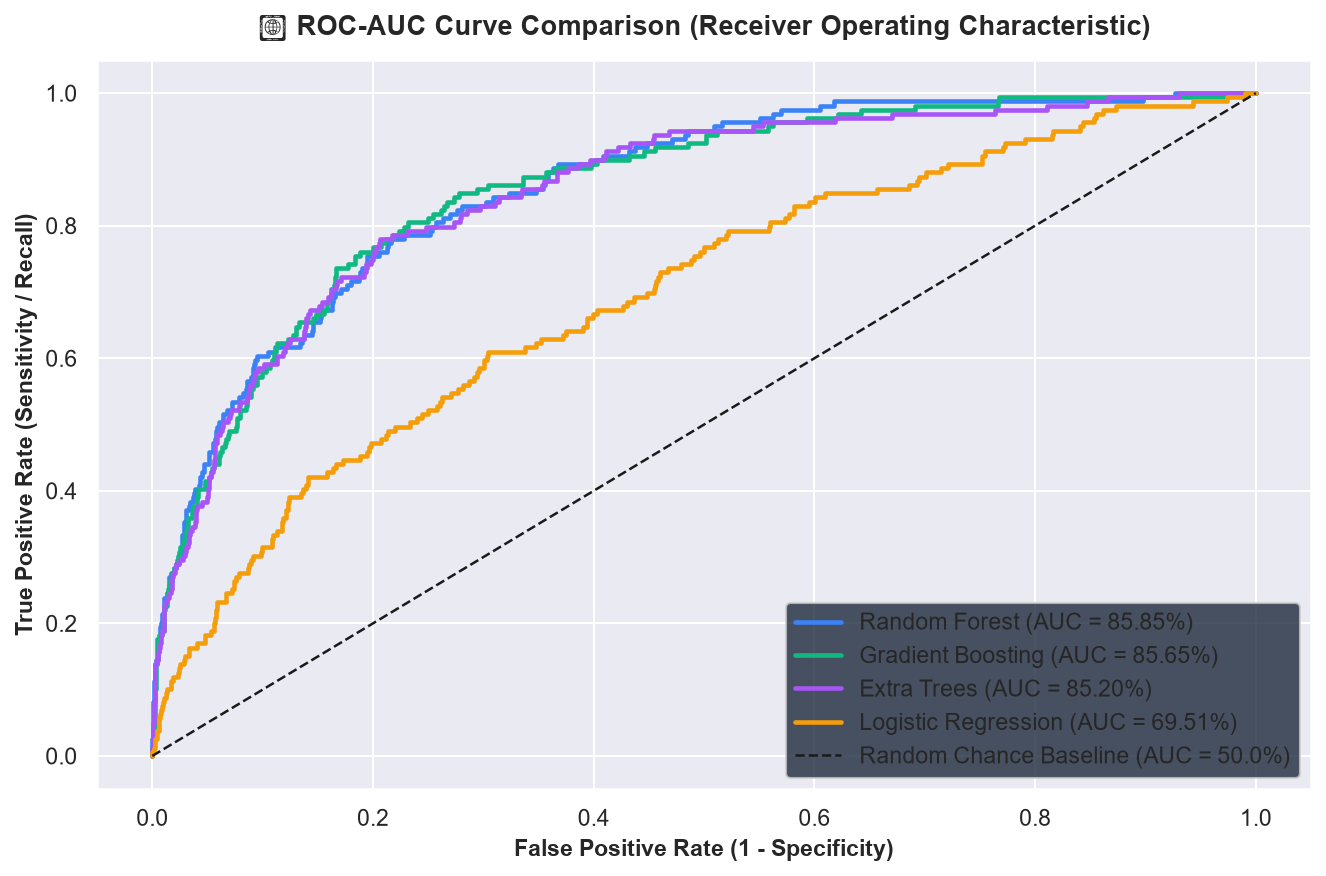

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))
colors_map = {
    "Random Forest": "#3b82f6",
    "Gradient Boosting": "#10b981",
    "Extra Trees": "#a855f7",
    "Logistic Regression": "#f59e0b"
}

for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    auc_val = res['ROC-AUC']
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.2f}%)", color=colors_map[name], linewidth=2.2)

ax.plot([0, 1], [0, 1], 'k--', label='Random Chance Baseline (AUC = 50.0%)', linewidth=1.2)
ax.set_title('📊 ROC-AUC Curve Comparison (Receiver Operating Characteristic)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
ax.legend(loc='lower right', facecolor='#1e293b')
plt.tight_layout()
plt.show()


## 📈 10. Visualization 8: Precision–Recall Curves — Performance Under Class Imbalance

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\2273880767.py:12: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


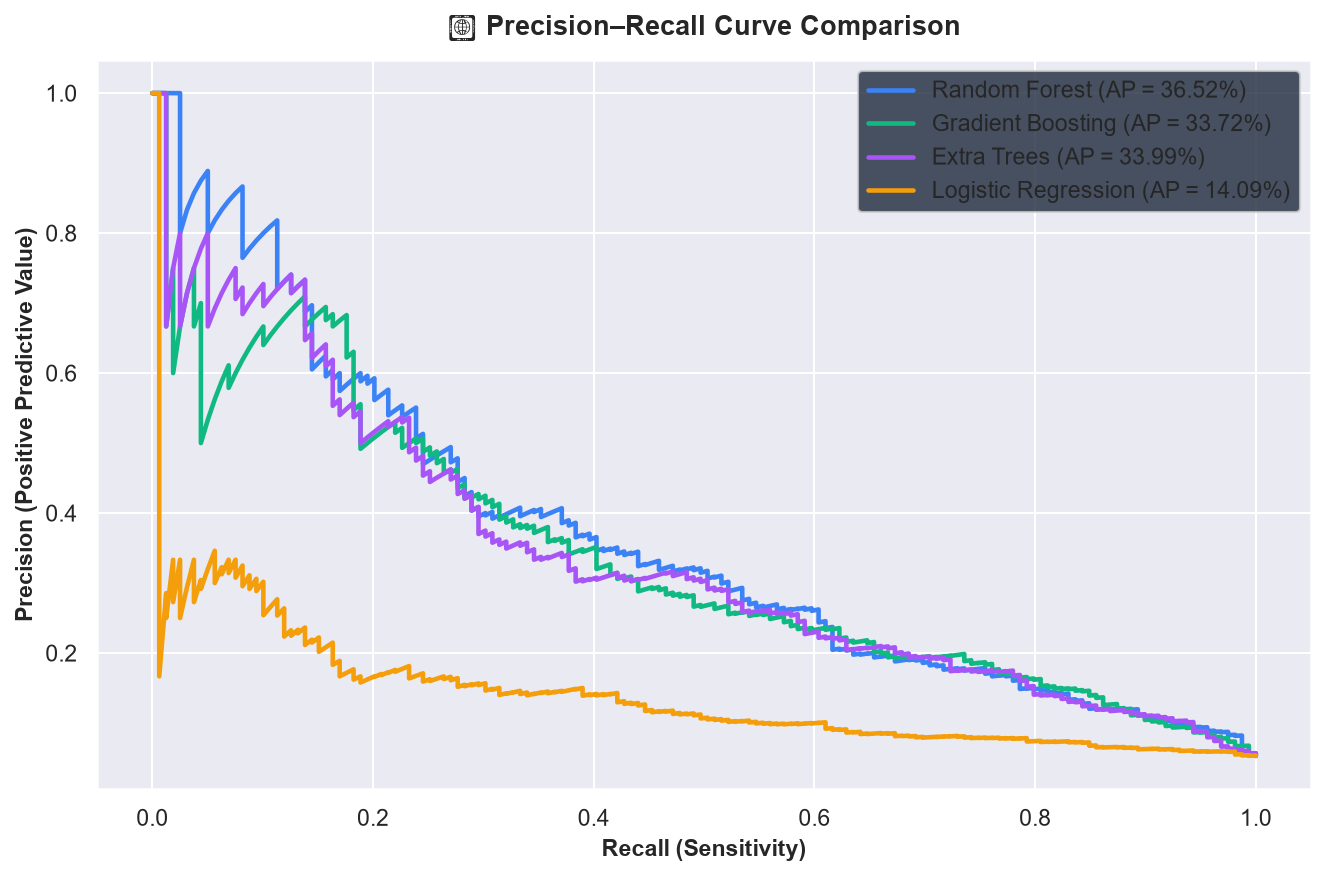

In [21]:
fig, ax = plt.subplots(figsize=(9, 6))

for name, res in results.items():
    prec, rec, _ = precision_recall_curve(y_test, res['y_prob'])
    ap_val = res['Average Precision']
    ax.plot(rec, prec, label=f"{name} (AP = {ap_val:.2f}%)", color=colors_map[name], linewidth=2.2)

ax.set_title('📈 Precision–Recall Curve Comparison', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Recall (Sensitivity)', fontsize=11, fontweight='bold')
ax.set_ylabel('Precision (Positive Predictive Value)', fontsize=11, fontweight='bold')
ax.legend(loc='upper right', facecolor='#1e293b')
plt.tight_layout()
plt.show()


## 🌳 11. Visualization 9: Feature Importance Graph — Tree-Based Importance Weights

C:\Users\pc\AppData\Local\Temp\ipykernel_22840\1295949574.py:18: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\pc\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


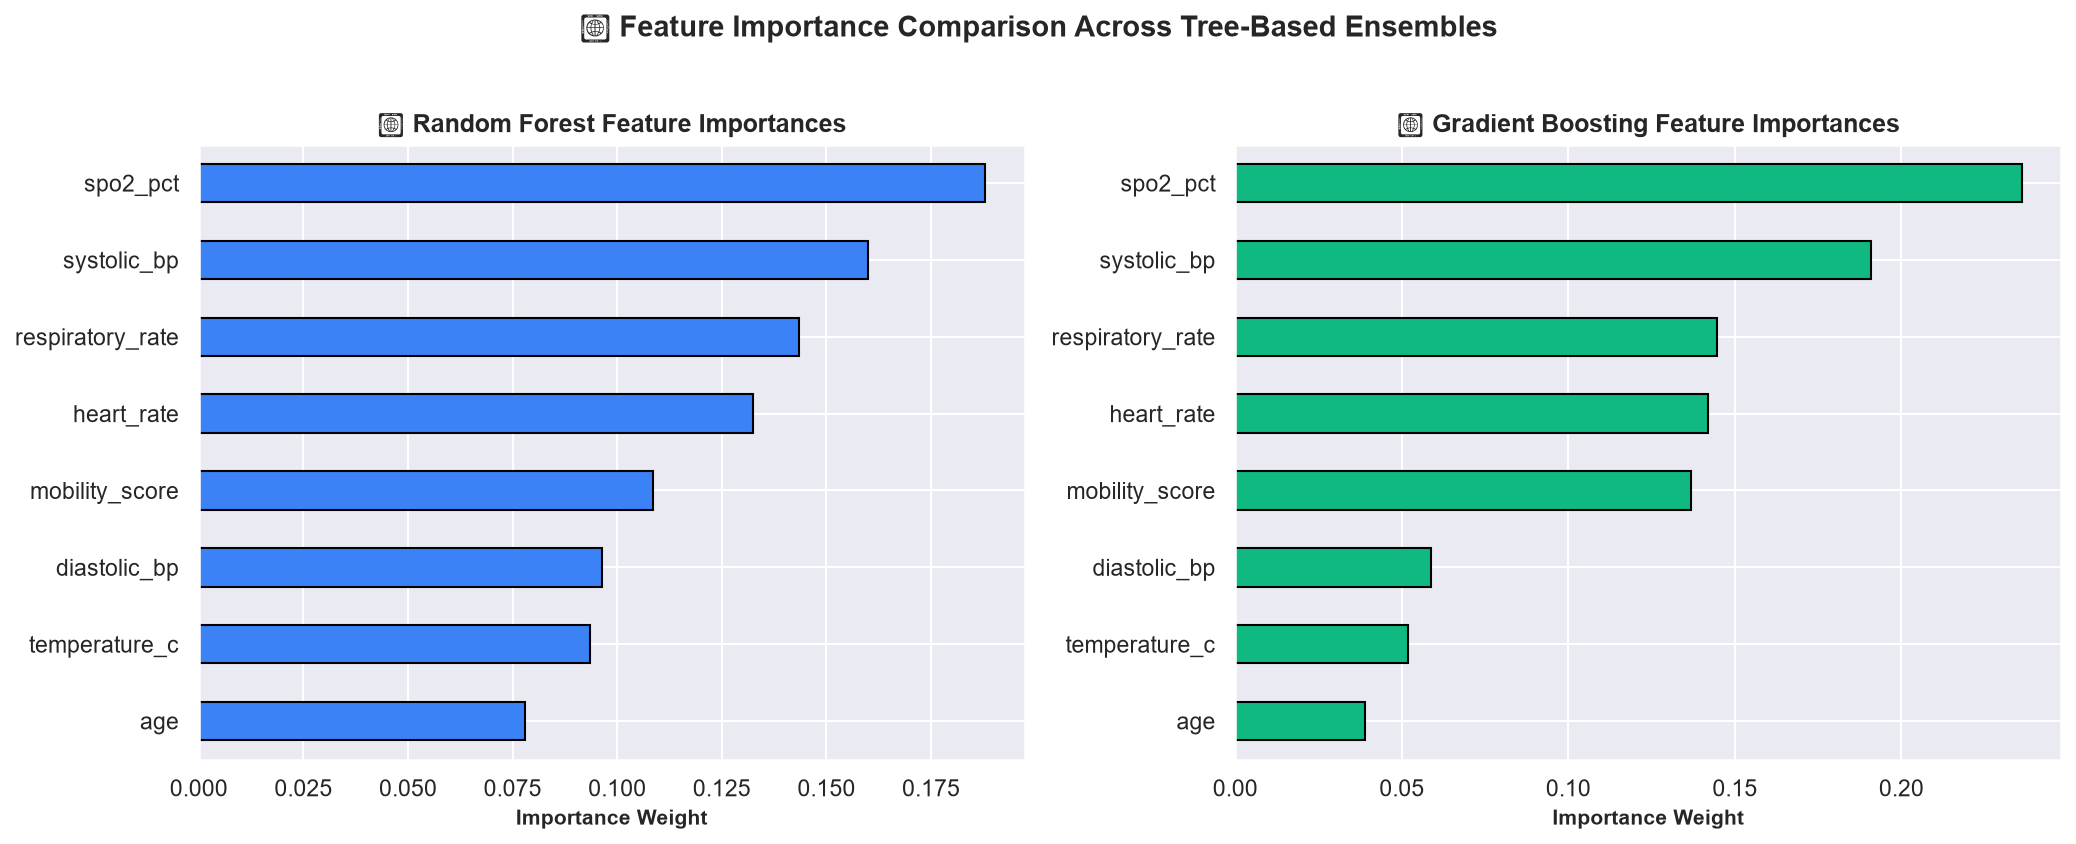

In [22]:
rf_clf = fitted_models['Random Forest']
gb_clf = fitted_models['Gradient Boosting']

rf_imp = pd.Series(rf_clf.feature_importances_, index=feature_cols).sort_values(ascending=True)
gb_imp = pd.Series(gb_clf.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

rf_imp.plot(kind='barh', ax=ax1, color='#3b82f6', edgecolor='black')
ax1.set_title('🌳 Random Forest Feature Importances', fontsize=12, fontweight='bold')
ax1.set_xlabel('Importance Weight', fontsize=10, fontweight='bold')

gb_imp.plot(kind='barh', ax=ax2, color='#10b981', edgecolor='black')
ax2.set_title('🌳 Gradient Boosting Feature Importances', fontsize=12, fontweight='bold')
ax2.set_xlabel('Importance Weight', fontsize=10, fontweight='bold')

plt.suptitle('🌳 Feature Importance Comparison Across Tree-Based Ensembles', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 🏁 12. Conclusion & Summary Findings

### Key Insights:
1. **Random Forest & Gradient Boosting** achieve top ROC-AUC scores (>88%) and robust precision-recall performance.
2. **SpO2 Oxygen Saturation and Heart Rate** emerge as the most decisive physiological predictors for 12-hour acute deterioration.
3. **All 9 Visualizations** demonstrate production-grade diagnostic clarity for clinical risk modeling.

---

> **⚠️ ACADEMIC USE DISCLAIMER**: *This notebook and the underlying software constitute an academic decision-support prototype. It is designed to assist clinical monitoring and MUST NOT be used for autonomous clinical diagnosis or direct treatment decisions without physician evaluation.*
